In [107]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

In [108]:
def load_covariate_file(file_path, sep="\t"):
    """
    Load phenotype/covariate file.
    
    Parameters
    ----------
    file_path : str
        Path to the phenotype/covariate file.
    sep : str
        Separator, default is tab.
    
    Returns
    -------
    df : pd.DataFrame
    """
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
    
    df = pd.read_csv(file_path, sep=sep)
    print(f"Loaded file: {file_path}")
    print(f"Shape: {df.shape}")
    return df

In [109]:
def identify_columns(
    df,
    id_candidates=("sampleid", "sample_id", "id"),
    sex_candidates=("sex", "gender"),
    age_candidates=("age_sd", "age"),
    phenotype_candidates=("cad", "bc", "T2D", "t2d", "bca")
):
    """
    Identify key columns in the dataframe.
    """
    cols = df.columns.tolist()
    lower_to_original = {c.lower(): c for c in cols}
    
    # ID column
    id_col = None
    for c in id_candidates:
        if c.lower() in lower_to_original:
            id_col = lower_to_original[c.lower()]
            break
    
    # Sex column
    sex_col = None
    for c in sex_candidates:
        if c.lower() in lower_to_original:
            sex_col = lower_to_original[c.lower()]
            break
    
    # Age column
    age_col = None
    for c in age_candidates:
        if c.lower() in lower_to_original:
            age_col = lower_to_original[c.lower()]
            break
    
    # PC columns
    pc_cols = [c for c in cols if c.lower().startswith("pc")]
    
    # phenotype columns
    phenotype_cols = []
    for c in phenotype_candidates:
        if c.lower() in lower_to_original:
            phenotype_cols.append(lower_to_original[c.lower()])
    
    results = {
        "id_col": id_col,
        "sex_col": sex_col,
        "age_col": age_col,
        "pc_cols": pc_cols,
        "phenotype_cols": phenotype_cols
    }
    
    print("Identified columns:")
    for k, v in results.items():
        print(f"  {k}: {v}")
    
    return results

In [110]:
def identify_columns(
    df,
    id_candidates=("sampleid", "sample_id", "id"),
    sex_candidates=("sex", "gender"),
    age_candidates=("age_sd", "age"),
    phenotype_candidates=("cad", "bc", "T2D", "t2d", "bca")
):
    """
    Identify key columns in the dataframe.
    """
    cols = df.columns.tolist()
    lower_to_original = {c.lower(): c for c in cols}
    
    # ID column
    id_col = None
    for c in id_candidates:
        if c.lower() in lower_to_original:
            id_col = lower_to_original[c.lower()]
            break
    
    # Sex column
    sex_col = None
    for c in sex_candidates:
        if c.lower() in lower_to_original:
            sex_col = lower_to_original[c.lower()]
            break
    
    # Age column
    age_col = None
    for c in age_candidates:
        if c.lower() in lower_to_original:
            age_col = lower_to_original[c.lower()]
            break
    
    # PC columns
    pc_cols = [c for c in cols if c.lower().startswith("pc")]
    
    # phenotype columns with de-duplication
    phenotype_cols = []
    seen = set()
    for c in phenotype_candidates:
        key = c.lower()
        if key in lower_to_original:
            original_col = lower_to_original[key]
            if original_col not in seen:
                phenotype_cols.append(original_col)
                seen.add(original_col)
    
    results = {
        "id_col": id_col,
        "sex_col": sex_col,
        "age_col": age_col,
        "pc_cols": pc_cols,
        "phenotype_cols": phenotype_cols
    }
    
    print("Identified columns:")
    for k, v in results.items():
        print(f"  {k}: {v}")
    
    return results

In [111]:
def add_bar_labels(ax, fmt="{:.0f}", fontsize=8, padding=2):
    """
    Add numeric labels on top of bars in a matplotlib Axes.
    """
    for container in ax.containers:
        labels = []
        for bar in container:
            height = bar.get_height()
            if pd.isna(height):
                labels.append("")
            else:
                labels.append(fmt.format(height))
        ax.bar_label(container, labels=labels, padding=padding, fontsize=fontsize)

In [112]:
def basic_overview(df, n=5):
    """
    Print basic overview of the dataframe.
    """
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    
    print("\nDtypes:")
    print(df.dtypes)
    
    print(f"\nFirst {n} rows:")
    display(df.head(n))

In [113]:
def missing_summary(df, sort=True, show_plot=True):
    """
    Summarize missing values.
    """
    summary = pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_rate": df.isna().mean().values
    })
    
    if sort:
        summary = summary.sort_values("missing_rate", ascending=False)
    
    display(summary)
    
    if show_plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.bar(summary["column"], summary["missing_rate"])
        ax.set_xticklabels(summary["column"], rotation=90)
        ax.set_ylabel("Missing rate")
        ax.set_title("Missingness by column")
        
        add_bar_labels(ax, fmt="{:.3f}", fontsize=8, padding=2)
        
        plt.tight_layout()
        plt.show()
    
    return summary

In [114]:
def summarize_covariates(df, sex_col=None, age_col=None, pc_cols=None):
    """
    Summarize covariates including sex, age, and PCs.
    """
    results = {}
    
    if sex_col is not None and sex_col in df.columns:
        sex_counts = df[sex_col].value_counts(dropna=False)
        print(f"\nSex distribution: {sex_col}")
        display(sex_counts)
        results["sex_counts"] = sex_counts
    
    if age_col is not None and age_col in df.columns:
        age_series = pd.to_numeric(df[age_col], errors="coerce")
        print(f"\nAge summary: {age_col}")
        display(age_series.describe())
        results["age_summary"] = age_series.describe()
    
    if pc_cols is not None and len(pc_cols) > 0:
        pc_df = df[pc_cols].apply(pd.to_numeric, errors="coerce")
        print("\nPC summary:")
        display(pc_df.describe())
        results["pc_summary"] = pc_df.describe()
    
    return results

In [115]:
def subset_female(df, sex_col="sex", female_values=("Female", "F", "female", "f", 0)):
    """
    Return female-only subset based on sex column.
    """
    if sex_col not in df.columns:
        raise ValueError(f"Sex column '{sex_col}' not found in dataframe.")
    
    female_mask = df[sex_col].isin(female_values)
    df_female = df.loc[female_mask].copy()
    
    print(f"Female-only subset: {df_female.shape[0]} / {df.shape[0]} samples retained.")
    return df_female

In [116]:
def summarize_phenotypes(
    df,
    phenotype_cols,
    sex_col=None,
    female_only_phenotypes=("bc", "bca", "breast_cancer")
):
    """
    Summarize binary phenotype columns.
    For breast cancer phenotypes, restrict to female samples only.
    """
    phenotype_cols = list(dict.fromkeys(phenotype_cols))  # de-duplicate while preserving order
    
    rows = []
    
    for col in phenotype_cols:
        col_lower = col.lower()
        
        # use female-only subset for breast cancer
        if col_lower in female_only_phenotypes:
            if sex_col is None:
                raise ValueError(f"Phenotype '{col}' requires sex_col for female-only filtering.")
            df_use = subset_female(df, sex_col=sex_col)
            phenotype_label = f"{col} (female only)"
        else:
            df_use = df
            phenotype_label = col
        
        s = pd.to_numeric(df_use[col], errors="coerce")
        n_total = len(s)
        n_missing = s.isna().sum()
        n_case = (s == 1).sum()
        n_control = (s == 0).sum()
        prevalence = n_case / (n_case + n_control) if (n_case + n_control) > 0 else np.nan
        
        rows.append({
            "phenotype": phenotype_label,
            "original_phenotype": col,
            "n_total": n_total,
            "n_missing": n_missing,
            "n_case": n_case,
            "n_control": n_control,
            "prevalence": prevalence
        })
    
    summary_df = pd.DataFrame(rows)
    display(summary_df)
    return summary_df

In [117]:
def plot_age_distribution(df, age_col):
    """
    Plot age distribution.
    """
    if age_col is None or age_col not in df.columns:
        print("Age column not found.")
        return
    
    age_series = pd.to_numeric(df[age_col], errors="coerce")
    
    plt.figure(figsize=(7, 4))
    plt.hist(age_series.dropna(), bins=40)
    plt.xlabel(age_col)
    plt.ylabel("Count")
    plt.title(f"Distribution of {age_col}")
    plt.tight_layout()
    plt.show()
    
def plot_sex_distribution(df, sex_col):
    """
    Plot sex distribution with value labels.
    """
    if sex_col is None or sex_col not in df.columns:
        print("Sex column not found.")
        return
    
    counts = df[sex_col].value_counts(dropna=False)
    
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_xlabel(sex_col)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {sex_col}")
    
    add_bar_labels(ax, fmt="{:.0f}")
    
    plt.tight_layout()
    plt.show()
    
def plot_phenotype_counts(summary_df):
    """
    Plot case/control counts for phenotypes, with value labels.
    """
    if summary_df is None or len(summary_df) == 0:
        print("No phenotype summary available.")
        return
    
    x = np.arange(len(summary_df))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - width/2, summary_df["n_case"], width, label="Case")
    ax.bar(x + width/2, summary_df["n_control"], width, label="Control")
    
    ax.set_xticks(x)
    ax.set_xticklabels(summary_df["phenotype"])
    ax.set_ylabel("Count")
    ax.set_title("Case / Control counts by phenotype")
    ax.legend()
    
    add_bar_labels(ax, fmt="{:.0f}")
    
    plt.tight_layout()
    plt.show()
    
def plot_pc_scatter(df, pc_cols, color_by=None):
    """
    Plot PC1 vs PC2 scatter.
    """
    if pc_cols is None or len(pc_cols) < 2:
        print("Need at least two PC columns.")
        return
    
    pc1 = pd.to_numeric(df[pc_cols[0]], errors="coerce")
    pc2 = pd.to_numeric(df[pc_cols[1]], errors="coerce")
    
    plt.figure(figsize=(6, 6))
    
    if color_by is not None and color_by in df.columns:
        categories = df[color_by].astype(str).fillna("NA")
        for cat in categories.unique():
            mask = categories == cat
            plt.scatter(pc1[mask], pc2[mask], s=10, alpha=0.6, label=cat)
        plt.legend()
    else:
        plt.scatter(pc1, pc2, s=10, alpha=0.6)
    
    plt.xlabel(pc_cols[0])
    plt.ylabel(pc_cols[1])
    plt.title(f"{pc_cols[0]} vs {pc_cols[1]}")
    plt.tight_layout()
    plt.show()
    
def check_bc_vs_sex(df, phenotype_col="bc", sex_col="sex"):
    """
    Cross-tab breast cancer phenotype against sex.
    """
    if phenotype_col not in df.columns:
        print(f"{phenotype_col} not found.")
        return
    if sex_col not in df.columns:
        print(f"{sex_col} not found.")
        return
    
    ctab = pd.crosstab(df[sex_col], df[phenotype_col], dropna=False)
    display(ctab)
    return ctab

In [118]:
def run_basic_eda(
    file_path,
    sep="\t",
    phenotype_candidates=("cad", "bc", "T2D", "t2d", "bca"),
    color_pc_by="sex"
):
    """
    Run a complete basic EDA pipeline.
    """
    # load
    df = load_covariate_file(file_path, sep=sep)
    
    # inspect columns
    info = identify_columns(
        df,
        phenotype_candidates=phenotype_candidates
    )
    
    # overview
    basic_overview(df)
    
    # missing
    miss_df = missing_summary(df, show_plot=True)
    
    # summarize covariates
    cov_results = summarize_covariates(
        df,
        sex_col=info["sex_col"],
        age_col=info["age_col"],
        pc_cols=info["pc_cols"]
    )
    
    # summarize phenotypes
    pheno_summary = summarize_phenotypes(
        df,
        info["phenotype_cols"],
        sex_col=info["sex_col"]
    )
    
    # plots
    plot_sex_distribution(df, info["sex_col"])
    plot_age_distribution(df, info["age_col"])
    plot_phenotype_counts(pheno_summary)
    plot_pc_scatter(df, info["pc_cols"], color_by=color_pc_by)
    
    return {
        "df": df,
        "column_info": info,
        "missing_summary": miss_df,
        "covariate_summary": cov_results,
        "phenotype_summary": pheno_summary
    }

Loaded file: /gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/phenotype_files/Training_Cov_file.txt
Shape: (5811, 16)
Identified columns:
  id_col: sampleid
  sex_col: sex
  age_col: age_sd
  pc_cols: ['PC1_sd', 'PC2_sd', 'PC3_sd', 'PC4_sd', 'PC5_sd', 'PC6_sd', 'PC7_sd', 'PC8_sd', 'PC9_sd', 'PC10_sd']
  phenotype_cols: ['cad', 'bc', 'T2D']
Shape: (5811, 16)

Columns:
['sampleid', 'sex', 'age_sd', 'PC1_sd', 'PC2_sd', 'PC3_sd', 'PC4_sd', 'PC5_sd', 'PC6_sd', 'PC7_sd', 'PC8_sd', 'PC9_sd', 'PC10_sd', 'cad', 'bc', 'T2D']

Dtypes:
sampleid        str
sex             str
age_sd      float64
PC1_sd      float64
PC2_sd      float64
PC3_sd      float64
PC4_sd      float64
PC5_sd      float64
PC6_sd      float64
PC7_sd      float64
PC8_sd      float64
PC9_sd      float64
PC10_sd     float64
cad           int64
bc            int64
T2D           int64
dtype: object

First 5 rows:


,sampleid,sex,age_sd,PC1_sd,PC2_sd,PC3_sd,PC4_sd,PC5_sd,PC6_sd,PC7_sd,PC8_sd,PC9_sd,PC10_sd,cad,bc,T2D
0,S-781185,Male,1.288303,-0.555962,0.480146,0.224748,0.241001,0.320088,1.938814,0.348092,0.387093,0.610129,-0.450001,1,0,0
1,S-312853,Female,1.591000,-0.482392,0.222560,-0.349030,-0.697747,-0.539562,0.463947,-0.214933,0.386187,-0.588972,-0.390756,0,0,0
2,S-879678,Male,0.077515,0.154176,-3.259585,1.898367,-0.280359,-0.868405,0.188799,2.969257,-4.082796,1.091930,1.139250,1,0,1
3,S-964332,Female,-0.770037,1.364458,0.080234,0.323463,-0.224608,1.842692,-0.409662,-1.222077,0.806165,-0.700859,0.216519,0,0,0
4,S-734060,Male,0.440751,-0.562651,0.332478,-0.273394,-1.414405,-0.311043,-0.842868,-0.864892,-0.473900,-1.954522,1.386096,1,0,0


,column,missing_count,missing_rate
0,sampleid,0,0.0
1,sex,0,0.0
2,age_sd,0,0.0
3,PC1_sd,0,0.0
4,PC2_sd,0,0.0
5,PC3_sd,0,0.0
6,PC4_sd,0,0.0
7,PC5_sd,0,0.0
8,PC6_sd,0,0.0
9,PC7_sd,0,0.0


/tmp/ipykernel_3471893/1464090982.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(summary["column"], rotation=90)


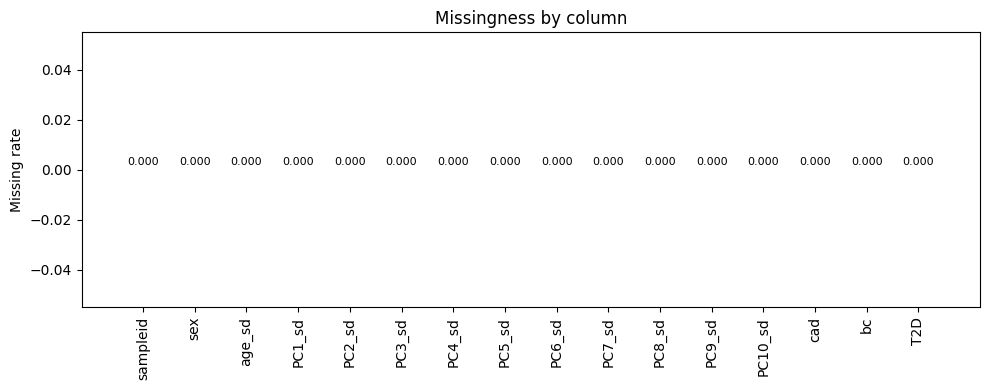


Sex distribution: sex


sex
Female     3308
Male       2502
Unknown       1
Name: count, dtype: int64


Age summary: age_sd


count    5811.000000
mean        0.010204
std         0.997093
min        -2.646759
25%        -0.709498
50%         0.138054
75%         0.803988
max         1.591000
Name: age_sd, dtype: float64


PC summary:


,PC1_sd,PC2_sd,PC3_sd,PC4_sd,PC5_sd,PC6_sd,PC7_sd,PC8_sd,PC9_sd,PC10_sd
count,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000,5811.000000
mean,-0.003522,0.006763,0.014583,-0.003894,-0.017188,0.012858,-0.004236,-0.011894,-0.020938,-0.002847
std,1.003297,1.003005,0.984889,0.997617,0.961858,1.006852,0.993320,1.003368,0.978468,1.004079
min,-0.777125,-3.501306,-5.439560,-1.976557,-1.615449,-2.254264,-4.678447,-5.162975,-3.855038,-4.702629
25%,-0.569057,0.255677,-0.203655,-0.696532,-0.377564,-0.707298,-0.499583,-0.463925,-0.626390,-0.621511
50%,-0.487572,0.397715,0.094193,-0.090975,-0.172993,-0.217176,-0.003565,-0.005200,-0.103529,-0.126981
75%,0.099441,0.469412,0.445963,0.719112,0.050578,0.446812,0.524418,0.434003,0.456085,0.472788
max,3.179651,0.806533,2.431000,2.400563,6.720766,3.994497,3.813062,8.344253,4.988417,8.676167


Female-only subset: 3308 / 5811 samples retained.


,phenotype,original_phenotype,n_total,n_missing,n_case,n_control,prevalence
0,cad,cad,5811,0,2313,3498,0.398038
1,bc (female only),bc,3308,0,602,2706,0.181983
2,T2D,T2D,5811,0,1701,4110,0.292721


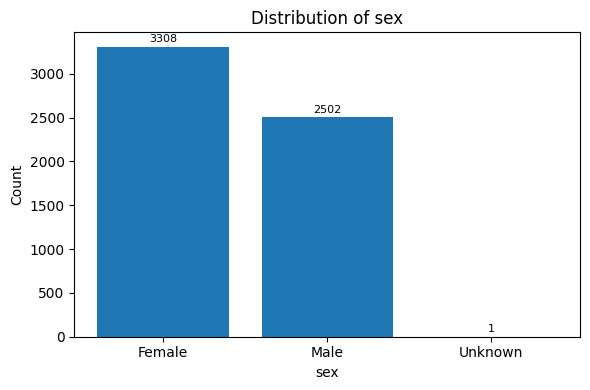

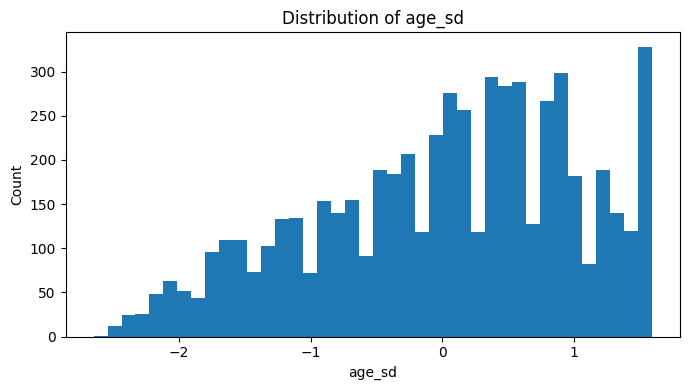

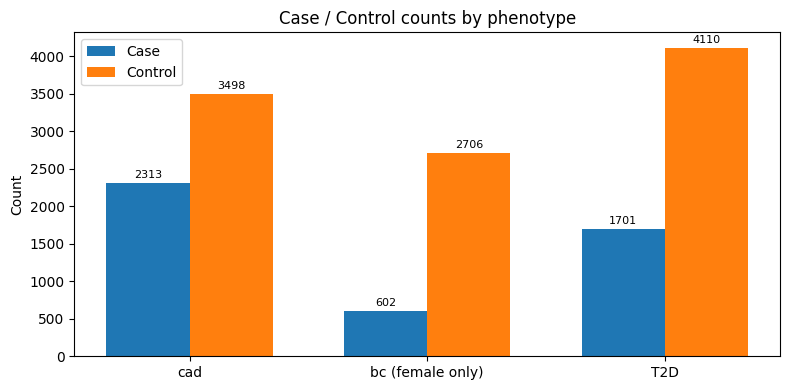

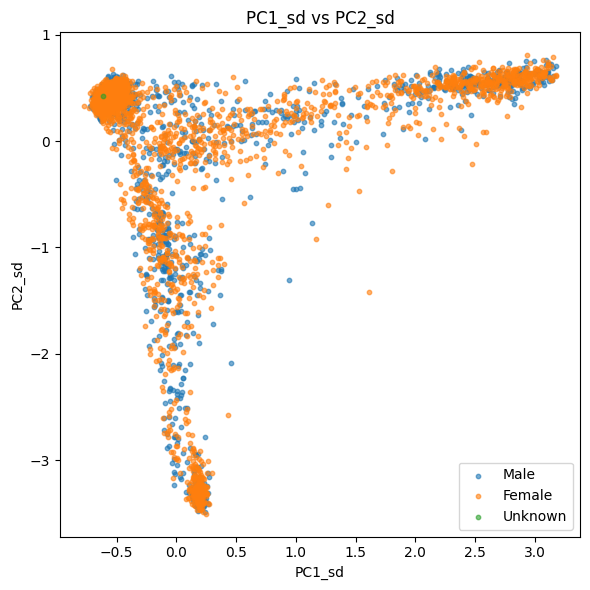

In [119]:
file_path = "/gpfs/data/deciphEHRlab/deciphEHRdream/training_phase/phenotype_files/Training_Cov_file.txt"

results = run_basic_eda(file_path)